⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Data ready...
🚀 Running Dual Keltner + RSI Strategy...

🎯 STRATEGY #15 - Dual Keltner + RSI
     Final Equity: 30111.1495
     Total Return: 2.0111
    CAGR (approx): 0.6449
     Max Drawdown: -0.1273
           Sharpe: 2.5256
           Trades: 194
          Winrate: 0.4948
    Avg PnL/Trade: 103.6657
    Profit Factor: 1.8542

💡 Estimated R:R: 1:1.89


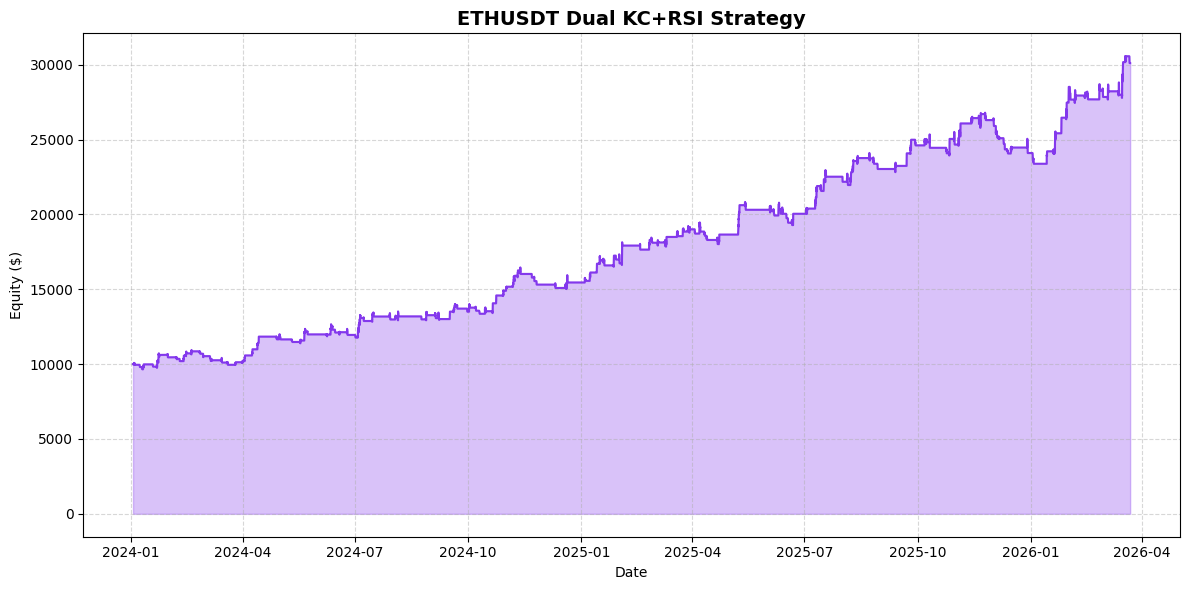


📊 Sample Trades:
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2024-01-04 06:00:00  SHORT  2223.790000  2238.800000  -43.030063    Time Exit   9956.969937
1 2024-01-08 06:00:00  SHORT  2178.953135  2206.426008 -149.354549    Stop Loss   9807.615388
2 2024-01-10 02:00:00   LONG  2398.640000  2346.746402 -147.114231    Stop Loss   9660.501157
3 2024-01-11 11:00:00   LONG  2516.237437  2663.846005  326.484946  Take Profit   9986.986103
4 2024-01-18 22:00:00  SHORT  2437.850047  2470.584069 -149.804792    Stop Loss   9837.181311
5 2024-01-22 10:00:00  SHORT  2426.938557  2376.171071  393.170096  Take Profit  10230.351407
6 2024-01-23 09:00:00  SHORT  2321.880000  2246.176863  348.737806  Take Profit  10579.089213
7 2024-01-24 03:00:00  SHORT  2223.350000  2213.450000   37.536718    Time Exit  10616.625931
8 2024-01-30 23:00:00   LONG  2369.250000  2341.233431 -159.249389    Stop Loss  10457.376542
9 2024-02-07 11:00:00   LONG  2378.244553 

In [1]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # Typical Price = (High + Low + Close) / 3
    data['Typical_Price'] = (data['High'] + data['Low'] + data['Close']) / 3
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_30'] = calc_atr(data['TR'], 30)
    data['ATR_50'] = calc_atr(data['TR'], 50)
    
    # RSI(49) on Typical Price
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_49'] = calc_rsi(data['Typical_Price'], 49)
    
    # Keltner Channel (50, dev=2.4)
    data['EMA_50'] = data['Close'].ewm(span=50, adjust=False).mean()
    data['ATR_50_KC'] = calc_atr(data['TR'], 50)
    data['KC_Upper_50'] = data['EMA_50'] + (2.4 * data['ATR_50_KC'])
    data['KC_Lower_50'] = data['EMA_50'] - (2.4 * data['ATR_50_KC'])
    
    # Keltner Channel (49, dev=1.5)
    data['EMA_49'] = data['Close'].ewm(span=49, adjust=False).mean()
    data['ATR_49'] = calc_atr(data['TR'], 49)
    data['KC_Upper_49'] = data['EMA_49'] + (1.5 * data['ATR_49'])
    data['KC_Lower_49'] = data['EMA_49'] - (1.5 * data['ATR_49'])
    
    # Highest/Lowest Close trong 10 nến
    data['Highest_Close_10'] = data['Close'].rolling(window=10).max()
    data['Lowest_Close_10'] = data['Close'].rolling(window=10).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class DualKCRSIBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        
        # Strategy Parameters
        self.risk_pct = 0.015  # 1.5%
        self.price_entry_mult = 2.4  # Entry buffer
        self.sl_coef = 1.8  # SL = 1.8 * ATR(20)
        self.tp_coef = 4.5  # TP = 4.5 * ATR(30)
        self.exit_after_bars = 16
        self.pending_expiration = 2
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                if self.position == 'LONG':
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                
                elif self.position == 'SHORT':
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                if i < 4:
                    self.append_equity(idx)
                    continue
                
                # Current Open
                open_current = current_bar['Open']
                
                # Dual KC Filter (shift=1)
                kc_upper_50_shift1 = self.df.iloc[i-1]['KC_Upper_50']
                kc_lower_50_shift1 = self.df.iloc[i-1]['KC_Lower_50']
                kc_upper_49_shift1 = self.df.iloc[i-1]['KC_Upper_49']
                kc_lower_49_shift1 = self.df.iloc[i-1]['KC_Lower_49']
                
                # RSI Momentum (shift=4 vs shift=3)
                rsi_shift4 = self.df.iloc[i-4]['RSI_49']
                rsi_shift3 = self.df.iloc[i-3]['RSI_49']
                
                # LONG SIGNAL (3 conditions)
                long_signal = (
                    open_current > kc_upper_50_shift1 and  # Above KC(50, 2.4)
                    rsi_shift4 < rsi_shift3 and            # RSI rising
                    open_current > kc_upper_49_shift1      # Above KC(49, 1.5)
                )
                
                # SHORT SIGNAL (3 conditions)
                short_signal = (
                    open_current < kc_lower_50_shift1 and  # Below KC(50, 2.4)
                    rsi_shift4 > rsi_shift3 and            # RSI falling
                    open_current < kc_lower_49_shift1      # Below KC(49, 1.5)
                )
                
                if not long_signal and not short_signal:
                    self.append_equity(idx)
                    continue
                
                # Entry parameters
                # Highest/Lowest shift=2, ATR shift=3
                highest_close_shift2 = self.df.iloc[i-2]['Highest_Close_10']
                lowest_close_shift2 = self.df.iloc[i-2]['Lowest_Close_10']
                atr_50_shift3 = self.df.iloc[i-3]['ATR_50']
                
                # SL/TP parameters (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]['ATR_20']
                atr_30_shift1 = self.df.iloc[i-1]['ATR_30']
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_close_shift2 + (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_30_shift1
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift2 - (self.price_entry_mult * atr_50_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_30_shift1
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        self.balance += pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        self.position = None
        self.qty = 0

# --- 4. METRICS ---
def calculate_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("🎯 STRATEGY #15 - Dual Keltner + RSI")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)
    
    # Calculate R:R
    rr = (metrics['Profit Factor'] * (1 - metrics['Winrate'])) / metrics['Winrate'] if metrics['Winrate'] > 0 else 0
    print(f"\n💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#8338EC')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#8338EC')
    
    plt.title(f"{symbol} Dual KC+RSI Strategy", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "22/03/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Data ready...")
        df_calc = calculate_indicators(df_raw)
        
        print("🚀 Running Dual Keltner + RSI Strategy...")
        bt = DualKCRSIBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())
            
            print("\n📈 Exit Reasons:")
            print(trades_df['Reason'].value_counts())
        else:
            print("⚠️ No trades.")
    else:
        print("❌ Insufficient data.")